Project root: D:\gpt\OcuVision-AI
Dataset: D:\gpt\OcuVision-AI\data\preprocessed
Results: D:\gpt\OcuVision-AI\results\vgg19
Checkpoint: D:\gpt\OcuVision-AI\models\vgg19_best_checkpoint.pth

Class mapping:
{'N': 0, 'D': 1, 'G': 2, 'C': 3, 'A': 4, 'H': 5, 'M': 6}

Total images: 10449

Class distribution:
class
N    2997
D    3128
G    1646
C    1008
A     511
H     420
M     739
Name: count, dtype: int64

Dataset split:
Train: 8359
Validation: 1045
Test: 1045

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.0 GB

Loading pretrained VGG19...
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to C:\Users\chede appliances/.cache\torch\hub\checkpoints\vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [01:37<00:00, 5.88MB/s] 


✓ VGG19 loaded


STARTING VGG19 TRAINING


Epoch 1/10:   0%|          | 0/523 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 1.0513 | Train Acc: 0.6144 | Train F1: 0.4904 | Val Loss: 0.9302 | Val Acc: 0.6804 | Val Macro F1: 0.5636 | Time: 8.00 min
  ✓ Best checkpoint saved (Val Macro F1 = 0.5636)


...


Epoch 8/10 | Train Loss: 0.4566 | Train Acc: 0.8329 | Train F1: 0.8389 | Val Loss: 0.5821 | Val Acc: 0.7885 | Val Macro F1: 0.7923 | Time: 7.37 min


Epoch 9/10:   0%|          | 0/523 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 0.4566 | Train Acc: 0.8372 | Train F1: 0.8363 | Val Loss: 0.5649 | Val Acc: 0.7914 | Val Macro F1: 0.7898 | Time: 7.03 min


Epoch 10/10:   0%|          | 0/523 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 0.4162 | Train Acc: 0.8557 | Train F1: 0.8589 | Val Loss: 0.4898 | Val Acc: 0.8258 | Val Macro F1: 0.8377 | Time: 7.60 min
  ✓ Best checkpoint saved (Val Macro F1 = 0.8377)


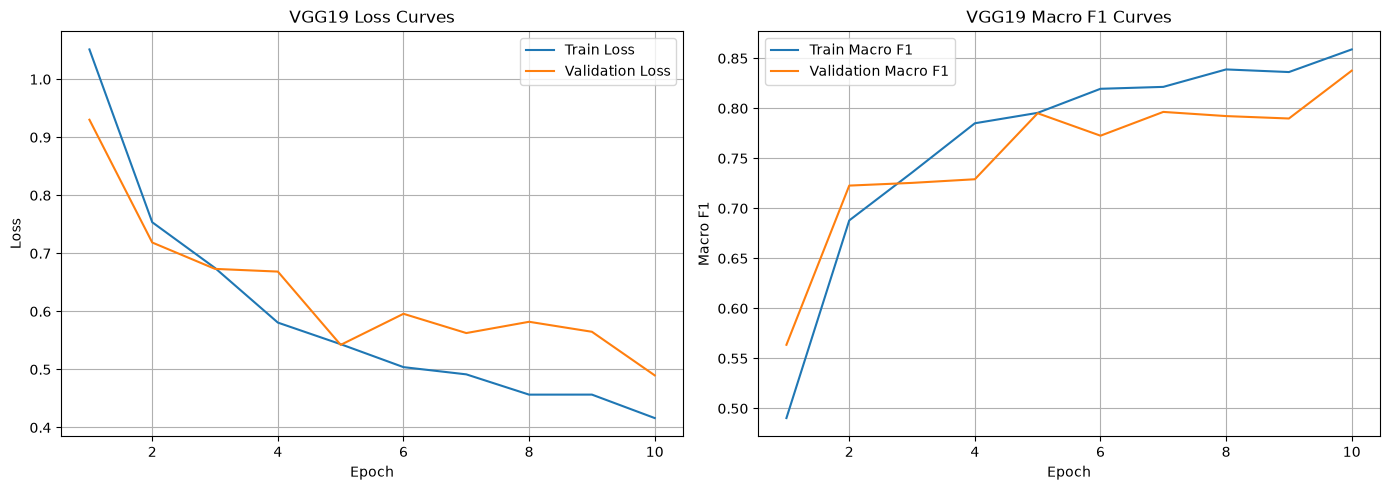



VGG19 TRAINING COMPLETE
Best validation Macro F1: 83.77%
Best epoch: 10
Training time: 1.41 hours
Checkpoint: D:\gpt\OcuVision-AI\models\vgg19_best_checkpoint.pth
History: D:\gpt\OcuVision-AI\results\vgg19\vgg19_training_history.csv


In [4]:
# ============================================================
# VGG19 LOCAL TRAINING - SETUP + DATASET + TRAINING
# OcuVision-AI
# ============================================================

from pathlib import Path
import random
import time
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vgg19, VGG19_Weights

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 2. Project root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

while (
    PROJECT_ROOT.name != "OcuVision-AI"
    and PROJECT_ROOT.parent != PROJECT_ROOT
):
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

# ------------------------------------------------------------
# 3. Paths
# ------------------------------------------------------------

DATA_DIR = PROJECT_ROOT / "data" / "preprocessed"
RESULTS_DIR = PROJECT_ROOT / "results" / "vgg19"
MODELS_DIR = PROJECT_ROOT / "models"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_PATH = (
    MODELS_DIR /
    "vgg19_best_checkpoint.pth"
)

HISTORY_PATH = (
    RESULTS_DIR /
    "vgg19_training_history.csv"
)

print("Dataset:", DATA_DIR)
print("Results:", RESULTS_DIR)
print("Checkpoint:", CHECKPOINT_PATH)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_DIR}"
    )

# ------------------------------------------------------------
# 4. Same class order as all previous models
# ------------------------------------------------------------

classes = [
    "N",
    "D",
    "G",
    "C",
    "A",
    "H",
    "M"
]

class_to_idx = {
    cls: idx
    for idx, cls in enumerate(classes)
}

idx_to_class = {
    idx: cls
    for cls, idx in class_to_idx.items()
}

print("\nClass mapping:")
print(class_to_idx)

# ------------------------------------------------------------
# 5. Collect dataset
# ------------------------------------------------------------

image_paths = []
labels = []

for cls in classes:

    class_dir = DATA_DIR / cls

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    for image_path in sorted(
        class_dir.glob("*")
    ):

        if image_path.suffix.lower() in [
            ".jpg",
            ".jpeg",
            ".png",
            ".bmp",
            ".webp"
        ]:

            image_paths.append(
                str(image_path)
            )

            labels.append(
                class_to_idx[cls]
            )

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df["class"] = df["label"].map(
    idx_to_class
)

print("\nTotal images:", len(df))

print("\nClass distribution:")

print(
    df["class"]
    .value_counts()
    .reindex(classes)
)

# ------------------------------------------------------------
# 6. SAME 80/10/10 stratified split
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

train_df = train_df.reset_index(
    drop=True
)

val_df = val_df.reset_index(
    drop=True
)

test_df = test_df.reset_index(
    drop=True
)

print("\nDataset split:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# ------------------------------------------------------------
# 7. Dataset class
# ------------------------------------------------------------

class OcularDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe.reset_index(
                drop=True
            )
        )

        self.transform = transform

    def __len__(self):
        return len(
            self.dataframe
        )

    def __getitem__(self, index):

        row = self.dataframe.iloc[
            index
        ]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        label = int(
            row["label"]
        )

        if self.transform:
            image = self.transform(
                image
            )

        return image, label

# ------------------------------------------------------------
# 8. VGG19 transforms
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])

# ------------------------------------------------------------
# 9. Datasets
# ------------------------------------------------------------

train_dataset = OcularDataset(
    train_df,
    train_transform
)

val_dataset = OcularDataset(
    val_df,
    eval_transform
)

test_dataset = OcularDataset(
    test_df,
    eval_transform
)

# ------------------------------------------------------------
# 10. DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 16
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# ------------------------------------------------------------
# 11. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("\nDevice:", device)

if device.type == "cuda":

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory:",
        round(
            torch.cuda
            .get_device_properties(0)
            .total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

# ------------------------------------------------------------
# 12. Load pretrained VGG19
# ------------------------------------------------------------

print("\nLoading pretrained VGG19...")

model = vgg19(
    weights=VGG19_Weights.IMAGENET1K_V1
)

# Replace final classifier
model.classifier[6] = nn.Linear(
    model.classifier[6].in_features,
    len(classes)
)

model = model.to(device)

print("✓ VGG19 loaded")

# ------------------------------------------------------------
# 13. Loss + optimizer
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# 14. Training configuration
# ------------------------------------------------------------

NUM_EPOCHS = 10

best_val_f1 = -1.0

history = []

if device.type == "cuda":

    scaler = torch.amp.GradScaler(
        "cuda"
    )

else:

    scaler = torch.amp.GradScaler(
        "cpu"
    )

# ------------------------------------------------------------
# 15. Validation function
# ------------------------------------------------------------

def evaluate_vgg19(
    model,
    loader
):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            if device.type == "cuda":

                with torch.amp.autocast(
                    "cuda"
                ):

                    outputs = model(
                        images
                    )

                    loss = criterion(
                        outputs,
                        labels
                    )

            else:

                outputs = model(
                    images
                )

                loss = criterion(
                    outputs,
                    labels
                )

            running_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    epoch_loss = (
        running_loss
        / len(loader.dataset)
    )

    accuracy = np.mean(
        np.array(all_labels)
        ==
        np.array(all_predictions)
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return (
        epoch_loss,
        accuracy,
        macro_f1
    )

# ------------------------------------------------------------
# 16. Training loop
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("STARTING VGG19 TRAINING")
print("=" * 70)

training_start = time.time()

for epoch in range(
    NUM_EPOCHS
):

    epoch_start = time.time()

    model.train()

    running_loss = 0.0

    all_train_labels = []
    all_train_predictions = []

    progress_bar = tqdm(
        train_loader,
        desc=(
            f"Epoch "
            f"{epoch + 1}/{NUM_EPOCHS}"
        )
    )

    for images, labels in progress_bar:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        if device.type == "cuda":

            with torch.amp.autocast(
                "cuda"
            ):

                outputs = model(
                    images
                )

                loss = criterion(
                    outputs,
                    labels
                )

            scaler.scale(
                loss
            ).backward()

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        all_train_predictions.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = (
        running_loss
        / len(train_loader.dataset)
    )

    train_accuracy = np.mean(
        np.array(all_train_labels)
        ==
        np.array(all_train_predictions)
    )

    train_macro_f1 = f1_score(
        all_train_labels,
        all_train_predictions,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss, val_accuracy, val_macro_f1 = (
        evaluate_vgg19(
            model,
            val_loader
        )
    )

    epoch_time = (
        time.time()
        - epoch_start
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "epoch_time_seconds": epoch_time
    })

    print(
        f"\nEpoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro F1: {val_macro_f1:.4f} | "
        f"Time: {epoch_time / 60:.2f} min"
    )

    # --------------------------------------------------------
    # Save best checkpoint
    # --------------------------------------------------------

    if val_macro_f1 > best_val_f1:

        best_val_f1 = val_macro_f1

        checkpoint = {
            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "epoch":
                epoch + 1,

            "best_val_macro_f1":
                best_val_f1,

            "classes":
                classes,

            "class_to_idx":
                class_to_idx,

            "seed":
                SEED
        }

        torch.save(
            checkpoint,
            CHECKPOINT_PATH
        )

        print(
            f"  ✓ Best checkpoint saved "
            f"(Val Macro F1 = "
            f"{best_val_f1:.4f})"
        )

# ------------------------------------------------------------
# 17. Save training history
# ------------------------------------------------------------

history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

total_training_time = (
    time.time()
    - training_start
)

# ------------------------------------------------------------
# 18. Training curves
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "VGG19 Loss Curves"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Loss"
)

axes[0].legend()

axes[0].grid(True)

axes[1].plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Train Macro F1"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro F1"
)

axes[1].set_title(
    "VGG19 Macro F1 Curves"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Macro F1"
)

axes[1].legend()

axes[1].grid(True)

plt.tight_layout()

training_curve_path = (
    RESULTS_DIR /
    "vgg19_training_curves.png"
)

plt.savefig(
    training_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
# ------------------------------------------------------------
# 19. Final training summary
# ------------------------------------------------------------

best_epoch = int(
    history_df.loc[
        history_df["val_macro_f1"].idxmax(),
        "epoch"
    ]
)

print("\n")
print("=" * 70)
print("VGG19 TRAINING COMPLETE")
print("=" * 70)

print(
    f"Best validation Macro F1: "
    f"{best_val_f1 * 100:.2f}%"
)

print(
    f"Best epoch: "
    f"{best_epoch}"
)

print(
    f"Training time: "
    f"{total_training_time / 3600:.2f} hours"
)

print(
    f"Checkpoint: "
    f"{CHECKPOINT_PATH}"
)

print(
    f"History: "
    f"{HISTORY_PATH}"
)

print("=" * 70)

Loading best VGG19 checkpoint...
✓ Best VGG19 checkpoint loaded
Best epoch: 10
Best validation Macro F1: 83.77%


Evaluating VGG19:   0%|          | 0/66 [00:00<?, ?it/s]



VGG19 FINAL TEST RESULTS
Test Loss          : 0.4162
Accuracy           : 84.40%
Macro Precision    : 86.82%
Macro Recall       : 83.44%
Macro F1           : 84.80%
Weighted F1        : 84.33%

Classification Report:


,precision,recall,f1-score,support
N,0.7590,0.9133,0.8290,300.000
D,0.8942,0.7827,0.8348,313.000
G,0.8405,0.8354,0.8379,164.000
C,1.0000,0.9703,0.9849,101.000
A,0.9808,1.0000,0.9903,51.000
H,0.8286,0.6905,0.7532,42.000
M,0.7742,0.6486,0.7059,74.000
accuracy,0.8440,0.8440,0.8440,0.844
macro avg,0.8682,0.8344,0.8480,1045.000
weighted avg,0.8503,0.8440,0.8433,1045.000


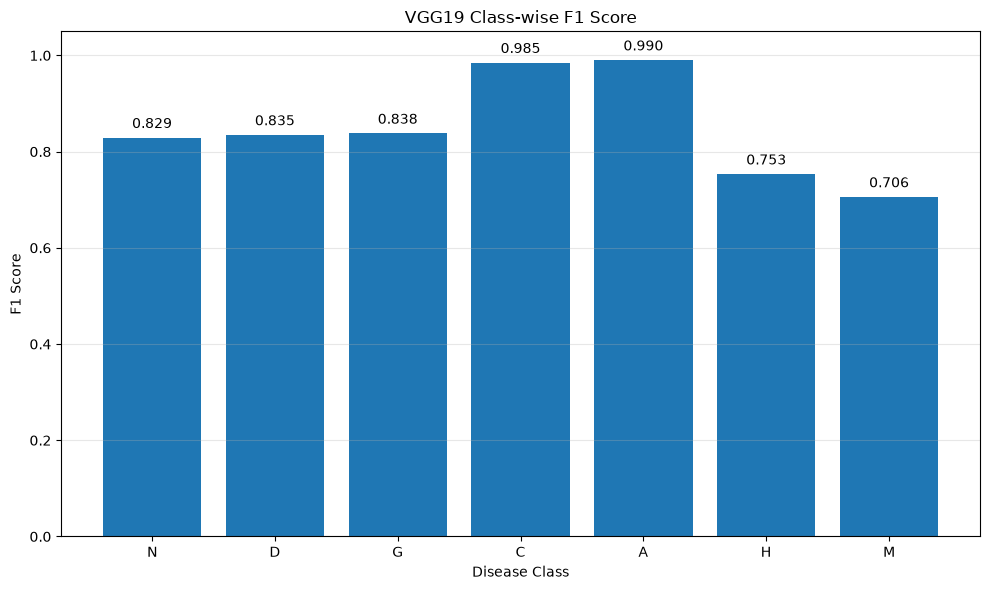

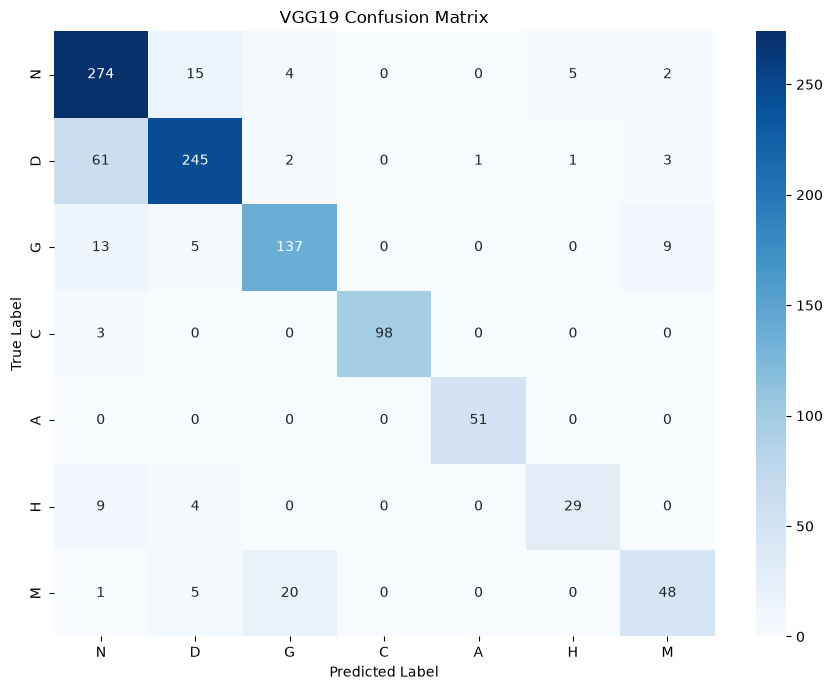

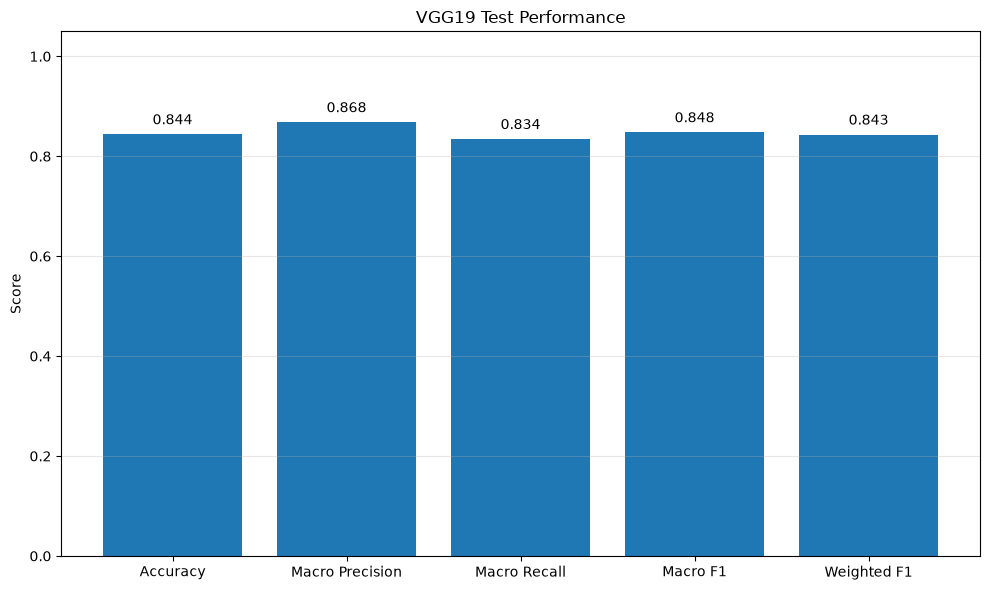



VGG19 EVALUATION COMPLETE

FINAL VGG19 METRICS
----------------------------------------
Accuracy        : 84.40%
Macro Precision : 86.82%
Macro Recall    : 83.44%
Macro F1        : 84.80%
Weighted F1     : 84.33%

Results saved to:
D:\gpt\OcuVision-AI\results\vgg19

Checkpoint:
D:\gpt\OcuVision-AI\models\vgg19_best_checkpoint.pth


In [5]:
# ============================================================
# VGG19 COMPLETE TEST EVALUATION + RESULTS
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torchvision.models import vgg19

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Recreate VGG19 architecture
# ------------------------------------------------------------

print("Loading best VGG19 checkpoint...")

best_model = vgg19(weights=None)

best_model.classifier[6] = nn.Linear(
    best_model.classifier[6].in_features,
    len(classes)
)

best_model = best_model.to(device)

# ------------------------------------------------------------
# 2. Load checkpoint
# ------------------------------------------------------------

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

print("✓ Best VGG19 checkpoint loaded")
print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation Macro F1:",
    f"{checkpoint['best_val_macro_f1'] * 100:.2f}%"
)

# ------------------------------------------------------------
# 3. Test inference
# ------------------------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

test_loss = 0.0

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Evaluating VGG19"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if device.type == "cuda":

            with torch.amp.autocast("cuda"):

                outputs = best_model(images)

                loss = criterion(
                    outputs,
                    labels
                )

        else:

            outputs = best_model(images)

            loss = criterion(
                outputs,
                labels
            )

        test_loss += (
            loss.item()
            * images.size(0)
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

all_labels = np.array(
    all_labels
)

all_predictions = np.array(
    all_predictions
)

all_probabilities = np.array(
    all_probabilities
)

test_loss = (
    test_loss
    / len(test_loader.dataset)
)

# ------------------------------------------------------------
# 4. Final metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

macro_precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# 5. Print final metrics
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VGG19 FINAL TEST RESULTS")
print("=" * 70)

print(f"Test Loss          : {test_loss:.4f}")
print(f"Accuracy           : {test_accuracy * 100:.2f}%")
print(f"Macro Precision    : {macro_precision * 100:.2f}%")
print(f"Macro Recall       : {macro_recall * 100:.2f}%")
print(f"Macro F1           : {macro_f1 * 100:.2f}%")
print(f"Weighted F1        : {weighted_f1 * 100:.2f}%")

print("=" * 70)

# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------

report_dict = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report_dict
).transpose()

report_path = (
    RESULTS_DIR /
    "vgg19_classification_report.csv"
)

report_df.to_csv(
    report_path
)

print("\nClassification Report:")
display(
    report_df.round(4)
)

# ------------------------------------------------------------
# 7. Class-wise F1
# ------------------------------------------------------------

classwise_f1_df = pd.DataFrame({
    "Class": classes,
    "F1 Score": [
        report_dict[cls]["f1-score"]
        for cls in classes
    ]
})

classwise_f1_path = (
    RESULTS_DIR /
    "vgg19_classwise_f1.csv"
)

classwise_f1_df.to_csv(
    classwise_f1_path,
    index=False
)

plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    classwise_f1_df["Class"],
    classwise_f1_df["F1 Score"]
)

plt.ylim(0, 1.05)
plt.xlabel("Disease Class")
plt.ylabel("F1 Score")
plt.title("VGG19 Class-wise F1 Score")

for bar, value in zip(
    bars,
    classwise_f1_df["F1 Score"]
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

classwise_f1_plot = (
    RESULTS_DIR /
    "vgg19_classwise_f1.png"
)

plt.savefig(
    classwise_f1_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(
    figsize=(9, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("VGG19 Confusion Matrix")

plt.tight_layout()

cm_path = (
    RESULTS_DIR /
    "vgg19_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. Test metrics plot
# ------------------------------------------------------------

metric_names = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

metric_values = [
    test_accuracy,
    macro_precision,
    macro_recall,
    macro_f1,
    weighted_f1
]

plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    metric_names,
    metric_values
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("VGG19 Test Performance")

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

metrics_plot_path = (
    RESULTS_DIR /
    "vgg19_test_metrics.png"
)

plt.savefig(
    metrics_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. Save metrics CSV + JSON
# ------------------------------------------------------------

metrics = {
    "model": "VGG19",
    "test_loss": float(test_loss),
    "accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_f1": float(weighted_f1),
    "best_validation_macro_f1": float(
        checkpoint["best_val_macro_f1"]
    ),
    "best_epoch": int(
        checkpoint["epoch"]
    ),
    "test_samples": int(
        len(test_dataset)
    )
}

metrics_df = pd.DataFrame([
    metrics
])

metrics_csv_path = (
    RESULTS_DIR /
    "vgg19_test_metrics.csv"
)

metrics_df.to_csv(
    metrics_csv_path,
    index=False
)

metrics_json_path = (
    RESULTS_DIR /
    "vgg19_test_metrics.json"
)

with open(
    metrics_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 11. Experiment summary
# ------------------------------------------------------------

summary_text = f"""
VGG19 Experiment Summary
=========================

Model:
VGG19 pretrained on ImageNet

Dataset:
ODIR-5K preprocessed ocular disease dataset

Classes:
{", ".join(classes)}

Dataset split:
Train: {len(train_dataset)}
Validation: {len(val_dataset)}
Test: {len(test_dataset)}

Random seed:
{SEED}

Input size:
224 x 224

Batch size:
{BATCH_SIZE}

Optimizer:
AdamW

Learning rate:
1e-4

Weight decay:
1e-4

Number of epochs:
{NUM_EPOCHS}

Best validation epoch:
{checkpoint["epoch"]}

Best validation Macro F1:
{checkpoint["best_val_macro_f1"] * 100:.2f}%

Final Test Results
------------------

Test Loss:
{test_loss:.4f}

Accuracy:
{test_accuracy * 100:.2f}%

Macro Precision:
{macro_precision * 100:.2f}%

Macro Recall:
{macro_recall * 100:.2f}%

Macro F1:
{macro_f1 * 100:.2f}%

Weighted F1:
{weighted_f1 * 100:.2f}%
"""

summary_path = (
    RESULTS_DIR /
    "vgg19_experiment_summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(summary_text)

# ------------------------------------------------------------
# 12. Final output
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VGG19 EVALUATION COMPLETE")
print("=" * 70)

print("\nFINAL VGG19 METRICS")
print("-" * 40)

print(
    f"Accuracy        : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Macro Precision : "
    f"{macro_precision * 100:.2f}%"
)

print(
    f"Macro Recall    : "
    f"{macro_recall * 100:.2f}%"
)

print(
    f"Macro F1        : "
    f"{macro_f1 * 100:.2f}%"
)

print(
    f"Weighted F1     : "
    f"{weighted_f1 * 100:.2f}%"
)

print("\nResults saved to:")
print(RESULTS_DIR)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

print("=" * 70)

In [2]:
# ============================================================
# VGG19 XAI SETUP
# Recreate exact project paths + test split
# ============================================================

from pathlib import Path
import pandas as pd
import torch

from sklearn.model_selection import train_test_split
from torchvision import transforms


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path(r"D:\gpt\OcuVision-AI")

DATA_DIR = (
    ROOT /
    "data" /
    "preprocessed"
)

RESULTS_DIR = (
    ROOT /
    "results" /
    "vgg19"
)

CHECKPOINT_PATH = (
    ROOT /
    "models" /
    "vgg19_best_checkpoint.pth"
)


# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)


# ============================================================
# 3. RANDOM SEED
# ============================================================

SEED = 42


# ============================================================
# 4. CLASSES
# ============================================================

classes = [
    "N",
    "D",
    "G",
    "C",
    "A",
    "H",
    "M"
]

class_to_idx = {
    cls: idx
    for idx, cls in enumerate(classes)
}

idx_to_class = {
    idx: cls
    for cls, idx in class_to_idx.items()
}


# ============================================================
# 5. CHECK PATHS
# ============================================================

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_DIR}"
    )

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"VGG19 checkpoint not found:\n"
        f"{CHECKPOINT_PATH}"
    )


RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 6. RECREATE DATAFRAME
# ============================================================

image_paths = []
labels = []


for cls in classes:

    class_dir = DATA_DIR / cls

    if not class_dir.exists():
        raise FileNotFoundError(
            f"Missing class directory:\n{class_dir}"
        )

    for image_path in sorted(
        class_dir.glob("*")
    ):

        if image_path.suffix.lower() in [
            ".jpg",
            ".jpeg",
            ".png",
            ".bmp",
            ".webp"
        ]:

            image_paths.append(
                str(image_path)
            )

            labels.append(
                class_to_idx[cls]
            )


df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})


df["class"] = df["label"].map(
    idx_to_class
)


# ============================================================
# 7. EXACT TRAIN / VAL / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=SEED
)


val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)


train_df = train_df.reset_index(
    drop=True
)

val_df = val_df.reset_index(
    drop=True
)

test_df = test_df.reset_index(
    drop=True
)


# ============================================================
# 8. VGG19 EVALUATION TRANSFORM
# ============================================================

eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print()
print("=" * 70)
print("EXACT VGG19 TEST SPLIT RECREATED")
print("=" * 70)

print(
    f"Total images : {len(df)}"
)

print(
    f"Train images : {len(train_df)}"
)

print(
    f"Val images   : {len(val_df)}"
)

print(
    f"Test images  : {len(test_df)}"
)

print("\nTest class distribution:")

print(
    test_df["class"]
    .value_counts()
    .reindex(classes)
)

print()
print("✓ test_df is ready")
print("✓ RESULTS_DIR is ready")
print("✓ CHECKPOINT_PATH is ready")
print("=" * 70)

Device: cuda

EXACT VGG19 TEST SPLIT RECREATED
Total images : 10449
Train images : 8359
Val images   : 1045
Test images  : 1045

Test class distribution:
class
N    300
D    313
G    164
C    101
A     51
H     42
M     74
Name: count, dtype: int64

✓ test_df is ready
✓ RESULTS_DIR is ready
✓ CHECKPOINT_PATH is ready


VGG19 GRAD-CAM / XAI
Grad-CAM output directory:
D:\gpt\OcuVision-AI\results\vgg19\gradcam

✓ VGG19 checkpoint loaded
Best epoch: 10
Best validation Macro F1: 83.77%

Grad-CAM target layer:
Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

Selected test images:
                                          image_path class
0  D:\gpt\OcuVision-AI\data\preprocessed\C\_335_9...     C
1  D:\gpt\OcuVision-AI\data\preprocessed\G\Glauco...     G
2  D:\gpt\OcuVision-AI\data\preprocessed\D\DR318.jpg     D
3  D:\gpt\OcuVision-AI\data\preprocessed\M\Myopia...     M
4  D:\gpt\OcuVision-AI\data\preprocessed\D\DR1199...     D
5  D:\gpt\OcuVision-AI\data\preprocessed\D\3977_l...     D
6  D:\gpt\OcuVision-AI\data\preprocessed\D\DR145.jpg     D
7  D:\gpt\OcuVision-AI\data\preprocessed\G\Glauco...     G
8  D:\gpt\OcuVision-AI\data\preprocessed\N\2927_l...     N
9  D:\gpt\OcuVision-AI\data\preprocessed\D\DR819.jpg     D
01/10 | True: C | Predicted: C | Confidence: 100.00%
02/10 | True: G | 

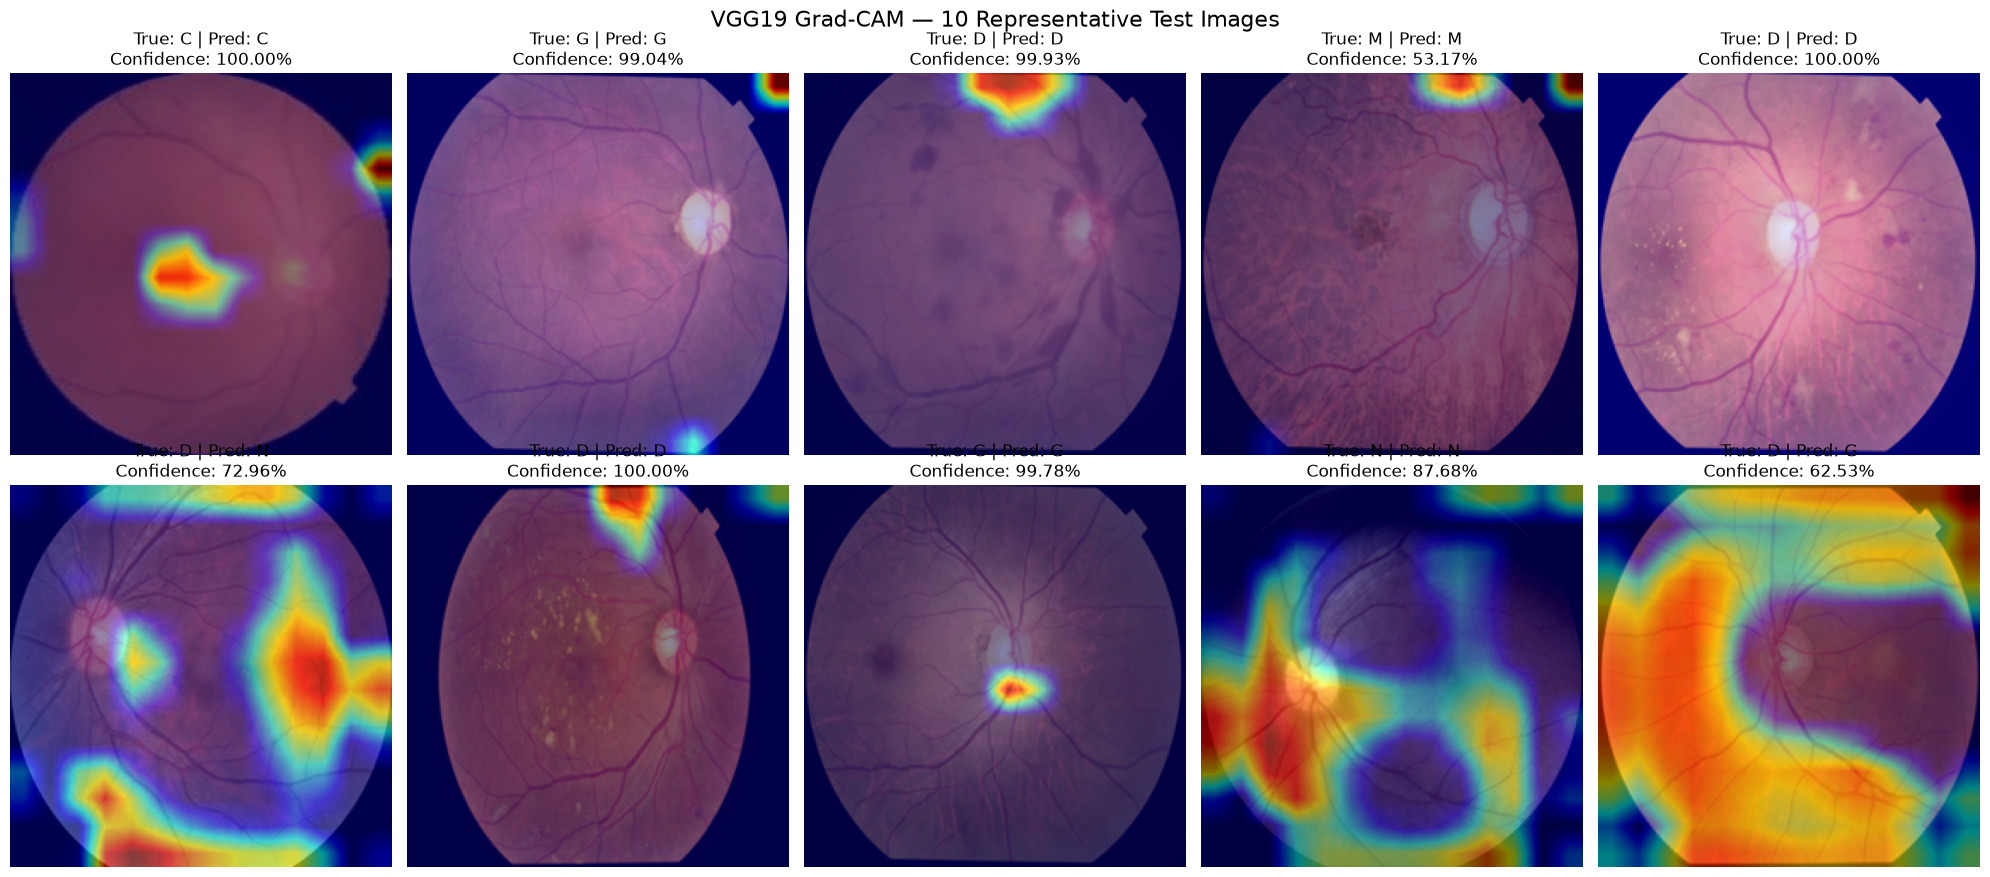



VGG19 GRAD-CAM COMPLETE
Images generated: 10
Correct predictions: 8/10
Grad-CAM directory: D:\gpt\OcuVision-AI\results\vgg19\gradcam
Summary CSV: D:\gpt\OcuVision-AI\results\vgg19\gradcam\gradcam_summary.csv
Contact sheet: D:\gpt\OcuVision-AI\results\vgg19\gradcam\vgg19_gradcam_contact_sheet.png


In [4]:
# ============================================================
# VGG19 GRAD-CAM / XAI
# 10 REPRESENTATIVE TEST IMAGES
# RESEARCH-QUALITY VERSION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image

from torchvision.models import vgg19

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = RESULTS_DIR / "gradcam"

GRADCAM_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("=" * 70)
print("VGG19 GRAD-CAM / XAI")
print("=" * 70)

print(
    f"Grad-CAM output directory:\n{GRADCAM_DIR}"
)


# ============================================================
# 2. RECREATE VGG19 AND LOAD BEST CHECKPOINT
# ============================================================

cam_model = vgg19(
    weights=None
)

cam_model.classifier[6] = nn.Linear(
    cam_model.classifier[6].in_features,
    len(classes)
)


# ------------------------------------------------------------
# Disable in-place ReLU
# Required for reliable Grad-CAM backward hooks
# ------------------------------------------------------------

for module in cam_model.modules():

    if isinstance(module, nn.ReLU):
        module.inplace = False


cam_model = cam_model.to(device)


# ============================================================
# 3. LOAD CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

cam_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

cam_model.eval()


print("\n✓ VGG19 checkpoint loaded")

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation Macro F1:",
    f"{checkpoint['best_val_macro_f1'] * 100:.2f}%"
)


# ============================================================
# 4. CORRECT VGG19 GRAD-CAM TARGET
#
# VGG19 final convolutional layer = features[34]
#
# features[-1] is the final ReLU and should NOT be used.
# ============================================================

target_layers = [
    cam_model.features[34]
]

print("\nGrad-CAM target layer:")
print(target_layers[0])


# ============================================================
# 5. CREATE GRAD-CAM
# ============================================================

cam = GradCAM(
    model=cam_model,
    target_layers=target_layers
)


# ============================================================
# 6. SELECT 10 REPRESENTATIVE TEST IMAGES
# ============================================================

num_samples = min(
    10,
    len(test_df)
)

sample_indices = np.linspace(
    0,
    len(test_df) - 1,
    num_samples,
    dtype=int
)

selected_test_df = (
    test_df
    .iloc[sample_indices]
    .reset_index(drop=True)
)


print("\nSelected test images:")

print(
    selected_test_df[
        ["image_path", "class"]
    ]
)


# ============================================================
# 7. GENERATE GRAD-CAM
# ============================================================

gradcam_records = []


for sample_number in range(
    1,
    num_samples + 1
):

    row = selected_test_df.iloc[
        sample_number - 1
    ]

    image_path = Path(
        row["image_path"]
    )

    true_class = row["class"]


    # --------------------------------------------------------
    # LOAD IMAGE
    # --------------------------------------------------------

    original_image = Image.open(
        image_path
    ).convert("RGB")


    resized_image = original_image.resize(
        (224, 224)
    )


    rgb_image = (
        np.array(
            resized_image
        ).astype(np.float32)
        / 255.0
    )


    # --------------------------------------------------------
    # PREPARE INPUT
    # --------------------------------------------------------

    input_tensor = (
        eval_transform(
            resized_image
        )
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    with torch.no_grad():

        outputs = cam_model(
            input_tensor
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predicted_index = torch.argmax(
            probabilities,
            dim=1
        ).item()

        predicted_class = idx_to_class[
            predicted_index
        ]

        confidence = probabilities[
            0,
            predicted_index
        ].item()


    # --------------------------------------------------------
    # GRAD-CAM TARGET
    # --------------------------------------------------------

    targets = [
        ClassifierOutputTarget(
            predicted_index
        )
    ]


    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]


    # --------------------------------------------------------
    # CREATE HEATMAP OVERLAY
    # --------------------------------------------------------

    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )


    # --------------------------------------------------------
    # SAVE IMAGE
    # --------------------------------------------------------

    output_filename = (
        f"{sample_number:02d}_"
        f"{true_class}_"
        f"{predicted_class}_"
        f"{confidence * 100:.2f}.png"
    )


    output_path = (
        GRADCAM_DIR /
        output_filename
    )


    Image.fromarray(
        visualization
    ).save(
        output_path
    )


    # --------------------------------------------------------
    # RECORD RESULT
    # --------------------------------------------------------

    gradcam_records.append({

        "sample": sample_number,

        "image_path": str(
            image_path
        ),

        "true_class": true_class,

        "predicted_class": predicted_class,

        "confidence": confidence,

        "correct": (
            predicted_class ==
            true_class
        ),

        "gradcam_path": str(
            output_path
        )
    })


    print(
        f"{sample_number:02d}/{num_samples} | "
        f"True: {true_class} | "
        f"Predicted: {predicted_class} | "
        f"Confidence: "
        f"{confidence * 100:.2f}%"
    )


# ============================================================
# 8. SAVE SUMMARY CSV
# ============================================================

gradcam_df = pd.DataFrame(
    gradcam_records
)


gradcam_csv = (
    GRADCAM_DIR /
    "gradcam_summary.csv"
)


gradcam_df.to_csv(
    gradcam_csv,
    index=False
)


# ============================================================
# 9. CREATE CONTACT SHEET
# ============================================================

fig, axes = plt.subplots(
    2,
    5,
    figsize=(20, 9)
)

axes = axes.flatten()


for ax, record in zip(
    axes,
    gradcam_records
):

    image = Image.open(
        record["gradcam_path"]
    )

    ax.imshow(image)

    ax.set_title(
        f"True: {record['true_class']} | "
        f"Pred: {record['predicted_class']}\n"
        f"Confidence: "
        f"{record['confidence'] * 100:.2f}%"
    )

    ax.axis("off")


plt.suptitle(
    "VGG19 Grad-CAM — 10 Representative Test Images",
    fontsize=16
)

plt.tight_layout()


contact_sheet_path = (
    GRADCAM_DIR /
    "vgg19_gradcam_contact_sheet.png"
)


plt.savefig(
    contact_sheet_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

correct_count = int(
    gradcam_df["correct"].sum()
)


print("\n")

print("=" * 70)
print("VGG19 GRAD-CAM COMPLETE")
print("=" * 70)

print(
    f"Images generated: "
    f"{len(gradcam_df)}"
)

print(
    f"Correct predictions: "
    f"{correct_count}/{len(gradcam_df)}"
)

print(
    f"Grad-CAM directory: "
    f"{GRADCAM_DIR}"
)

print(
    f"Summary CSV: "
    f"{gradcam_csv}"
)

print(
    f"Contact sheet: "
    f"{contact_sheet_path}"
)

print("=" * 70)

External image found:
D:\gpt\OcuVision-AI\data\external_images\demo_fundus_image.jpg

✓ VGG19 checkpoint loaded

Image: demo_fundus_image.jpg
Original size: (512, 512)


VGG19 EXTERNAL IMAGE PREDICTION
Predicted class : A
Confidence      : 99.99%

Class probabilities:
----------------------------------------
N: 0.00%
D: 0.01%
G: 0.00%
C: 0.00%
A: 99.99%
H: 0.00%
M: 0.00%


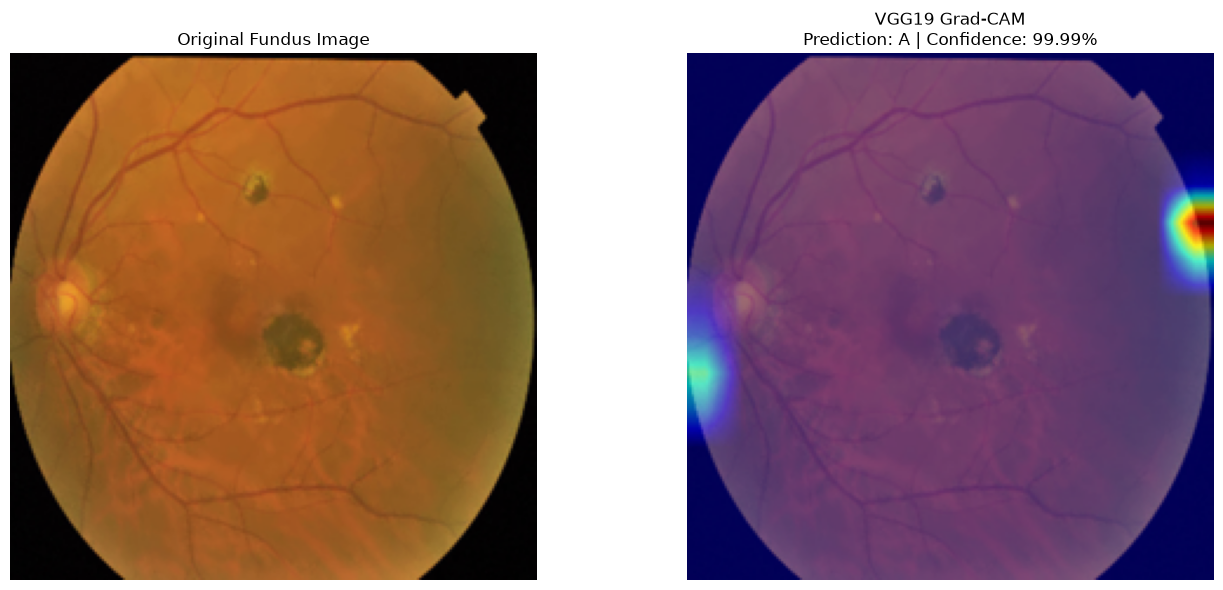



VGG19 EXTERNAL INFERENCE COMPLETE
Image       : demo_fundus_image.jpg
Prediction  : A
Confidence  : 99.99%

Grad-CAM saved to:
D:\gpt\OcuVision-AI\results\vgg19\external_xai\vgg19_external_demo_fundus_image_A_99.99.png

Probabilities saved to:
D:\gpt\OcuVision-AI\results\vgg19\external_xai\vgg19_external_demo_fundus_image_probabilities.csv


In [5]:
# ============================================================
# VGG19 EXTERNAL IMAGE INFERENCE + GRAD-CAM
# FRONTEND-READY PIPELINE
# ============================================================

from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image

from torchvision.models import vgg19

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


# ============================================================
# 1. EXTERNAL IMAGE DIRECTORY
# ============================================================

EXTERNAL_DIR = (
    ROOT /
    "data" /
    "external_images"
)

EXTERNAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


# ============================================================
# 2. FIND EXTERNAL IMAGE
# ============================================================

external_images = sorted(
    [
        p
        for p in EXTERNAL_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
    ]
)


# ============================================================
# 3. CREATE DEMO IMAGE IF NEEDED
# ============================================================

if len(external_images) == 0:

    print(
        "No external image found."
    )

    print(
        "Creating demo image from dataset..."
    )

    dataset_images = sorted(
        [
            p
            for p in DATA_DIR.rglob("*")
            if p.is_file()
            and p.suffix.lower() in image_extensions
        ]
    )

    if len(dataset_images) == 0:

        raise FileNotFoundError(
            f"No images found in:\n{DATA_DIR}"
        )

    source_image = dataset_images[0]

    demo_image_path = (
        EXTERNAL_DIR /
        "demo_fundus_image.jpg"
    )

    shutil.copy2(
        source_image,
        demo_image_path
    )

    EXTERNAL_IMAGE_PATH = (
        demo_image_path
    )

    print(
        f"Demo image created:\n"
        f"{EXTERNAL_IMAGE_PATH}"
    )

else:

    EXTERNAL_IMAGE_PATH = (
        external_images[0]
    )

    print(
        f"External image found:\n"
        f"{EXTERNAL_IMAGE_PATH}"
    )


# ============================================================
# 4. LOAD VGG19
# ============================================================

external_model = vgg19(
    weights=None
)


external_model.classifier[6] = nn.Linear(
    external_model.classifier[6].in_features,
    len(classes)
)


# Disable inplace ReLU for Grad-CAM
for module in external_model.modules():

    if isinstance(module, nn.ReLU):
        module.inplace = False


external_model = external_model.to(
    device
)


# ============================================================
# 5. LOAD BEST CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)


external_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)


external_model.eval()


print(
    "\n✓ VGG19 checkpoint loaded"
)


# ============================================================
# 6. LOAD IMAGE
# ============================================================

original_image = Image.open(
    EXTERNAL_IMAGE_PATH
).convert("RGB")


print(
    f"\nImage: "
    f"{EXTERNAL_IMAGE_PATH.name}"
)

print(
    f"Original size: "
    f"{original_image.size}"
)


# ============================================================
# 7. PREPARE IMAGE
# ============================================================

resized_image = original_image.resize(
    (224, 224)
)


rgb_image = (
    np.array(
        resized_image
    ).astype(np.float32)
    / 255.0
)


input_tensor = (
    eval_transform(
        resized_image
    )
    .unsqueeze(0)
    .to(device)
)


# ============================================================
# 8. PREDICTION
# ============================================================

with torch.no_grad():

    outputs = external_model(
        input_tensor
    )

    probabilities = torch.softmax(
        outputs,
        dim=1
    )[0]

    predicted_index = torch.argmax(
        probabilities
    ).item()

    predicted_class = idx_to_class[
        predicted_index
    ]

    confidence = probabilities[
        predicted_index
    ].item()


# ============================================================
# 9. DISPLAY PREDICTION
# ============================================================

print("\n")
print("=" * 70)
print("VGG19 EXTERNAL IMAGE PREDICTION")
print("=" * 70)

print(
    f"Predicted class : "
    f"{predicted_class}"
)

print(
    f"Confidence      : "
    f"{confidence * 100:.2f}%"
)

print("=" * 70)


# ============================================================
# 10. ALL 7 CLASS PROBABILITIES
# ============================================================

probability_records = []

print("\nClass probabilities:")
print("-" * 40)

for index, class_name in enumerate(classes):

    probability = probabilities[
        index
    ].item()

    probability_records.append({

        "class": class_name,

        "probability": probability
    })

    print(
        f"{class_name}: "
        f"{probability * 100:.2f}%"
    )


# ============================================================
# 11. GRAD-CAM
#
# VGG19 final convolutional layer = features[34]
# ============================================================

target_layers = [
    external_model.features[34]
]


external_cam = GradCAM(
    model=external_model,
    target_layers=target_layers
)


targets = [
    ClassifierOutputTarget(
        predicted_index
    )
]


grayscale_cam = external_cam(
    input_tensor=input_tensor,
    targets=targets
)[0]


# ============================================================
# 12. CREATE XAI OVERLAY
# ============================================================

visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)


# ============================================================
# 13. DISPLAY ORIGINAL + XAI
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)


axes[0].imshow(
    resized_image
)

axes[0].set_title(
    "Original Fundus Image"
)

axes[0].axis("off")


axes[1].imshow(
    visualization
)

axes[1].set_title(
    f"VGG19 Grad-CAM\n"
    f"Prediction: {predicted_class} | "
    f"Confidence: "
    f"{confidence * 100:.2f}%"
)

axes[1].axis("off")


plt.tight_layout()

plt.show()


# ============================================================
# 14. SAVE RESULTS
# ============================================================

EXTERNAL_XAI_DIR = (
    RESULTS_DIR /
    "external_xai"
)

EXTERNAL_XAI_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Save Grad-CAM
# ------------------------------------------------------------

output_path = (
    EXTERNAL_XAI_DIR /
    f"vgg19_external_"
    f"{EXTERNAL_IMAGE_PATH.stem}_"
    f"{predicted_class}_"
    f"{confidence * 100:.2f}.png"
)


Image.fromarray(
    visualization
).save(
    output_path
)


# ------------------------------------------------------------
# Save probabilities
# ------------------------------------------------------------

probability_df = pd.DataFrame(
    probability_records
)


probability_csv = (
    EXTERNAL_XAI_DIR /
    f"vgg19_external_"
    f"{EXTERNAL_IMAGE_PATH.stem}_"
    f"probabilities.csv"
)


probability_df.to_csv(
    probability_csv,
    index=False
)


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n")

print("=" * 70)
print("VGG19 EXTERNAL INFERENCE COMPLETE")
print("=" * 70)

print(
    f"Image       : "
    f"{EXTERNAL_IMAGE_PATH.name}"
)

print(
    f"Prediction  : "
    f"{predicted_class}"
)

print(
    f"Confidence  : "
    f"{confidence * 100:.2f}%"
)

print(
    "\nGrad-CAM saved to:"
)

print(output_path)

print(
    "\nProbabilities saved to:"
)

print(probability_csv)

print("=" * 70)